In [88]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import  (
      accuracy_score, precision_score, recall_score, f1_score,
      confusion_matrix, classification_report, roc_auc_score,
      roc_curve
)

import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')

print("libraries imported successfully!")

libraries imported successfully!


In [89]:
df = pd.read_csv(
    r"C:\Users\koura\OneDrive\Desktop\Loan_default.csv\Loan_default.csv"
)


In [90]:
df.head()

,LoanID,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default
0,I38PQUQS96,56,85994,50587,520,80,4,15.23,36,0.44,Bachelor's,Full-time,Divorced,Yes,Yes,Other,Yes,0
1,HPSK72WA7R,69,50432,124440,458,15,1,4.81,60,0.68,Master's,Full-time,Married,No,No,Other,Yes,0
2,C1OZ6DPJ8Y,46,84208,129188,451,26,3,21.17,24,0.31,Master's,Unemployed,Divorced,Yes,Yes,Auto,No,1
3,V2KKSFM3UN,32,31713,44799,743,0,3,7.07,24,0.23,High School,Full-time,Married,No,No,Business,No,0
4,EY08JDHTZP,60,20437,9139,633,8,4,6.51,48,0.73,Bachelor's,Unemployed,Divorced,No,Yes,Auto,No,0


In [91]:
df.columns

Index(['LoanID', 'Age', 'Income', 'LoanAmount', 'CreditScore',
       'MonthsEmployed', 'NumCreditLines', 'InterestRate', 'LoanTerm',
       'DTIRatio', 'Education', 'EmploymentType', 'MaritalStatus',
       'HasMortgage', 'HasDependents', 'LoanPurpose', 'HasCoSigner',
       'Default'],
      dtype='str')

In [92]:
df.dtypes

LoanID                str
Age                 int64
Income              int64
LoanAmount          int64
CreditScore         int64
MonthsEmployed      int64
NumCreditLines      int64
InterestRate      float64
LoanTerm            int64
DTIRatio          float64
Education             str
EmploymentType        str
MaritalStatus         str
HasMortgage           str
HasDependents         str
LoanPurpose           str
HasCoSigner           str
Default             int64
dtype: object

In [93]:
df.duplicated().sum()

np.int64(0)

In [94]:
df.describe()

,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Default
count,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000
mean,43.498306,82499.304597,127578.865512,574.264346,59.541976,2.501036,13.492773,36.025894,0.500212,0.116128
std,14.990258,38963.013729,70840.706142,158.903867,34.643376,1.117018,6.636443,16.969330,0.230917,0.320379
min,18.000000,15000.000000,5000.000000,300.000000,0.000000,1.000000,2.000000,12.000000,0.100000,0.000000
25%,31.000000,48825.500000,66156.000000,437.000000,30.000000,2.000000,7.770000,24.000000,0.300000,0.000000
50%,43.000000,82466.000000,127556.000000,574.000000,60.000000,2.000000,13.460000,36.000000,0.500000,0.000000
75%,56.000000,116219.000000,188985.000000,712.000000,90.000000,3.000000,19.250000,48.000000,0.700000,0.000000
max,69.000000,149999.000000,249999.000000,849.000000,119.000000,4.000000,25.000000,60.000000,0.900000,1.000000


In [95]:
df['Default'].value_counts()

Default
0    225694
1     29653
Name: count, dtype: int64

<Axes: >

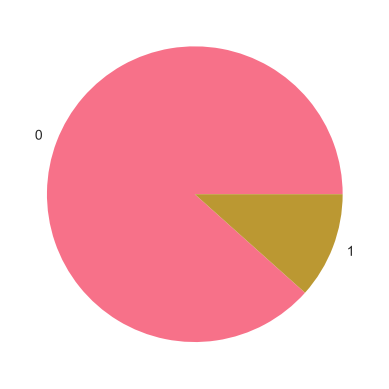

In [96]:
df['Default'].value_counts().plot(kind='pie')

<Axes: xlabel='Default'>

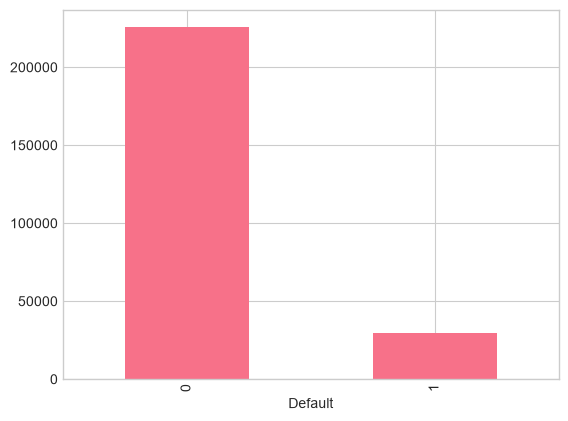

In [97]:
df['Default'].value_counts().plot(kind='bar')

In [98]:
df.select_dtypes(exclude='str').columns

Index(['Age', 'Income', 'LoanAmount', 'CreditScore', 'MonthsEmployed',
       'NumCreditLines', 'InterestRate', 'LoanTerm', 'DTIRatio', 'Default'],
      dtype='str')

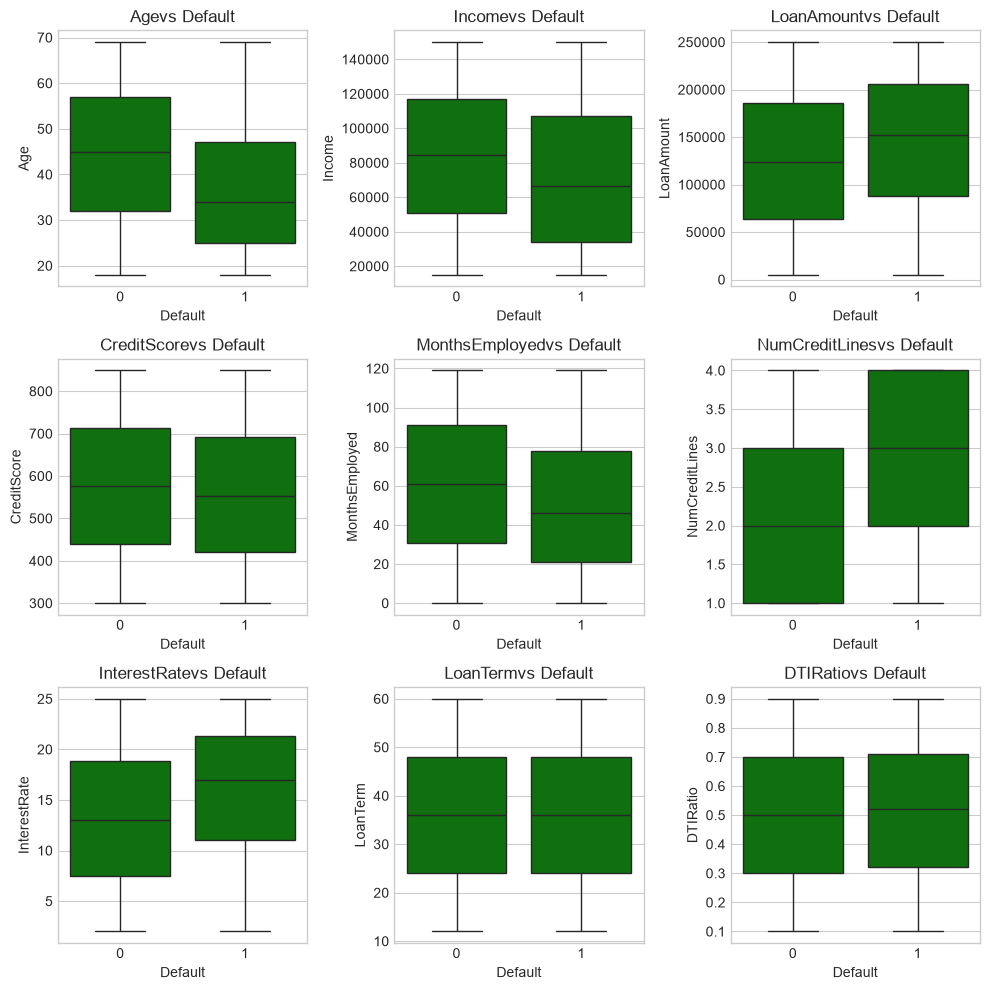

In [99]:
numerical_cols=['Age', 'Income', 'LoanAmount', 'CreditScore', 'MonthsEmployed',
       'NumCreditLines', 'InterestRate', 'LoanTerm', 'DTIRatio']

fig, axs=plt.subplots(3,3,figsize=(10,10))
axs= axs.flatten()
for index, column_name in enumerate(numerical_cols):
    sns.boxplot(data=df,y=column_name,x='Default', ax=axs[index],color='g')
    axs[index].set_title(f'{column_name} vs Default')
    axs[index].set_title(f'{column_name}vs Default')
    plt.tight_layout()

In [100]:
# correlation 

plt.figure(figsize=(10,8))
df[numerical_cols]

,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio
0,56,85994,50587,520,80,4,15.23,36,0.44
1,69,50432,124440,458,15,1,4.81,60,0.68
2,46,84208,129188,451,26,3,21.17,24,0.31
3,32,31713,44799,743,0,3,7.07,24,0.23
4,60,20437,9139,633,8,4,6.51,48,0.73
...,...,...,...,...,...,...,...,...,...
255342,19,37979,210682,541,109,4,14.11,12,0.85
255343,32,51953,189899,511,14,2,11.55,24,0.21
255344,56,84820,208294,597,70,3,5.29,60,0.50
255345,42,85109,60575,809,40,1,20.90,48,0.44


<Figure size 1000x800 with 0 Axes>

In [101]:
plt.figure(figsize=(10,8))
df[numerical_cols+['Default']].corr()

,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Default
Age,1.000000,-0.001244,-0.002213,-0.000548,-0.000341,-0.000890,-0.001127,0.000263,-0.004689,-0.167783
Income,-0.001244,1.000000,-0.000865,-0.001430,0.002675,-0.002016,-0.002303,-0.000998,0.000205,-0.099119
LoanAmount,-0.002213,-0.000865,1.000000,0.001261,0.002817,0.000794,-0.002291,0.002538,0.001122,0.086659
CreditScore,-0.000548,-0.001430,0.001261,1.000000,0.000613,0.000016,0.000436,0.001130,-0.001039,-0.034166
MonthsEmployed,-0.000341,0.002675,0.002817,0.000613,1.000000,0.001267,0.000096,-0.001166,0.001765,-0.097374
NumCreditLines,-0.000890,-0.002016,0.000794,0.000016,0.001267,1.000000,-0.000297,-0.000226,-0.000586,0.028330
InterestRate,-0.001127,-0.002303,-0.002291,0.000436,0.000096,-0.000297,1.000000,0.000892,0.000575,0.131273
LoanTerm,0.000263,-0.000998,0.002538,0.001130,-0.001166,-0.000226,0.000892,1.000000,0.002273,0.000545
DTIRatio,-0.004689,0.000205,0.001122,-0.001039,0.001765,-0.000586,0.000575,0.002273,1.000000,0.019236
Default,-0.167783,-0.099119,0.086659,-0.034166,-0.097374,0.028330,0.131273,0.000545,0.019236,1.000000


<Figure size 1000x800 with 0 Axes>

<Axes: >

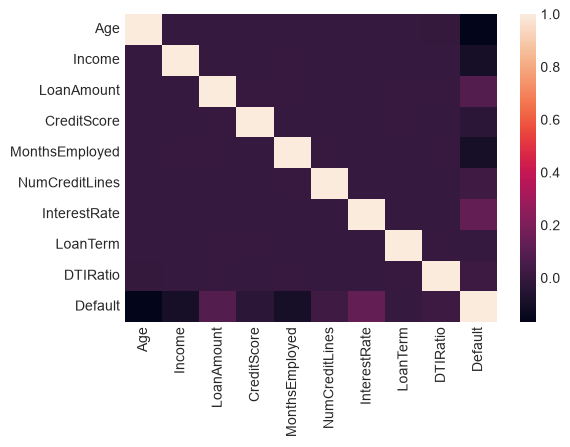

In [102]:
plt.figure(figsize=(6,4))
sns.heatmap(df[numerical_cols+['Default']].corr())

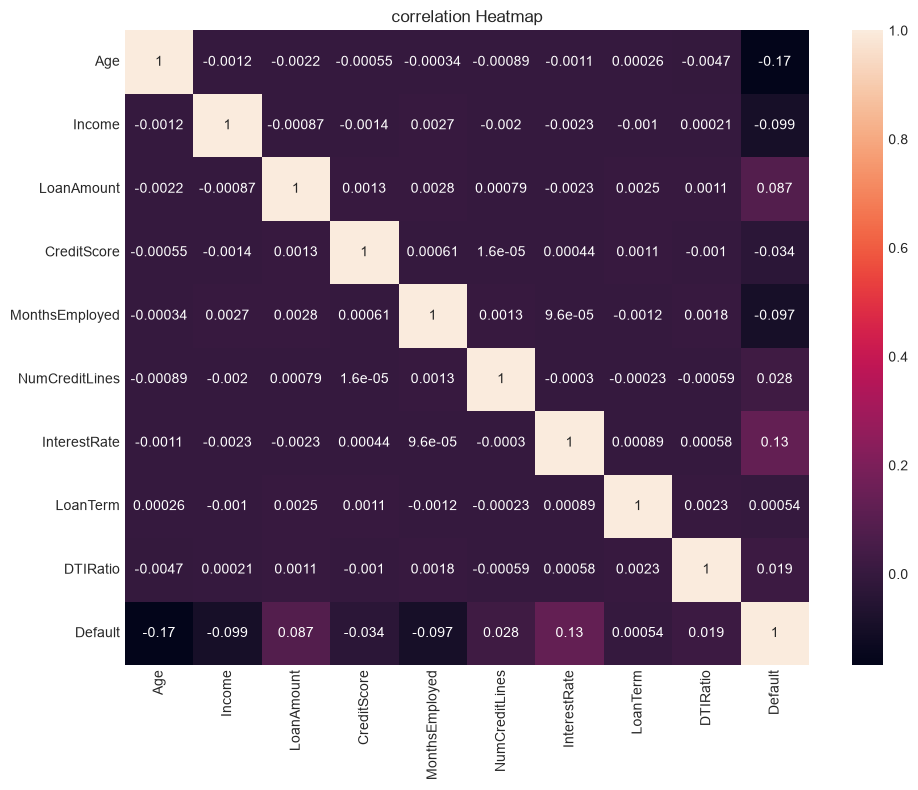

In [103]:

plt.figure(figsize=(10,8))
sns.heatmap(df[numerical_cols+['Default']].corr(),annot=True)
plt.title('correlation Heatmap')
plt.tight_layout()
plt.show()

In [104]:
#data preprocessing
df.drop('LoanID',axis=1, inplace=True)

In [105]:
X= df.drop('Default',axis=1)
Y= df['Default']

In [106]:
df.head()

,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default
0,56,85994,50587,520,80,4,15.23,36,0.44,Bachelor's,Full-time,Divorced,Yes,Yes,Other,Yes,0
1,69,50432,124440,458,15,1,4.81,60,0.68,Master's,Full-time,Married,No,No,Other,Yes,0
2,46,84208,129188,451,26,3,21.17,24,0.31,Master's,Unemployed,Divorced,Yes,Yes,Auto,No,1
3,32,31713,44799,743,0,3,7.07,24,0.23,High School,Full-time,Married,No,No,Business,No,0
4,60,20437,9139,633,8,4,6.51,48,0.73,Bachelor's,Unemployed,Divorced,No,Yes,Auto,No,0


In [107]:
categorical_column=X.select_dtypes(include='str').columns.to_list()
numerical_columns=X.select_dtypes(exclude='str').columns.to_list()
Label_Encoders={}

for col in categorical_column:
    le=LabelEncoder()
    X[col]= le.fit_transform(X[col].astype(str))
    
    Label_Encoders[col]= le
    print(f'encoded{col}:{dict(zip(le.classes_,le.transform(le.classes_)))}')

encodedEducation:{"Bachelor's": np.int64(0), 'High School': np.int64(1), "Master's": np.int64(2), 'PhD': np.int64(3)}
encodedEmploymentType:{'Full-time': np.int64(0), 'Part-time': np.int64(1), 'Self-employed': np.int64(2), 'Unemployed': np.int64(3)}
encodedMaritalStatus:{'Divorced': np.int64(0), 'Married': np.int64(1), 'Single': np.int64(2)}
encodedHasMortgage:{'No': np.int64(0), 'Yes': np.int64(1)}
encodedHasDependents:{'No': np.int64(0), 'Yes': np.int64(1)}
encodedLoanPurpose:{'Auto': np.int64(0), 'Business': np.int64(1), 'Education': np.int64(2), 'Home': np.int64(3), 'Other': np.int64(4)}
encodedHasCoSigner:{'No': np.int64(0), 'Yes': np.int64(1)}


In [108]:
x_train, x_test,y_train,y_test=train_test_split(
       X,Y,test_size=0.2,random_state=22

)

In [109]:
scaler= StandardScaler()
X_train_scaled=x_train.copy()
X_test_scaled=x_test.copy()

X_train_scaled[numerical_cols]=scaler.fit_transform(x_train[numerical_cols])
X_test_scaled[numerical_cols]=scaler.fit_transform(x_test[numerical_cols])




In [110]:
lr=LogisticRegression(class_weight='balanced',
max_iter= 100,solver='saga', n_jobs=-1)
lr.fit(X_train_scaled,y_train)
y_pred=lr.predict(X_train_scaled)
y_pred_proba=lr.predict(X_train_scaled)



In [111]:
from sklearn.metrics import (ConfusionMatrixDisplay,confusion_matrix,
classification_report, accuracy_score, precision_score,recall_score,roc_curve,roc_auc_score, f1_score)


In [112]:
model = LogisticRegression(max_iter=1000)

model.fit(x_train , y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [121]:
y_pred = model.predict(x_test)

In [ ]:
print("x_test:",len(x_test))
print("y_test:",len(y_test))
print("y_pred:",len(y_pred))

x_test: 51070
y_test: 51070
y_pred: 51070


In [115]:
print(f'accuracy_score: {accuracy_score(y_test,y_pred)}')
print(f'precision_score: {precision_score(y_test,y_pred)}')
print(f'recall_score:{recall_score(y_test,y_pred)}')
print(f'f1_score: {f1_score(y_test,y_pred )}')
print(f'roc_auc_score: {roc_auc_score(y_test,y_pred)}')

accuracy_score: 0.8845114548658704
precision_score: 0.6
recall_score:0.03220395840322039
f1_score: 0.061127029608404965
roc_auc_score: 0.5146831621403349


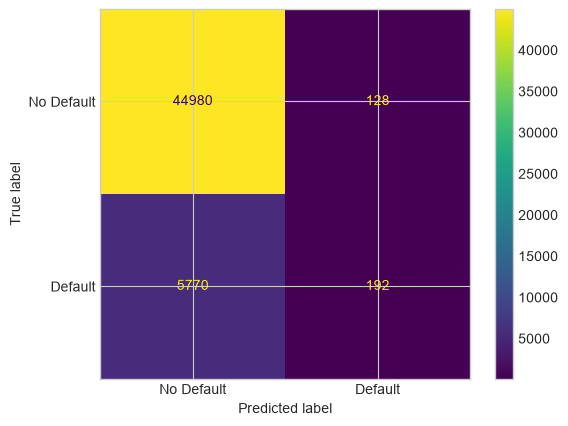

In [116]:
cm=confusion_matrix(y_test,y_pred)

dis=ConfusionMatrixDisplay(confusion_matrix=cm,
display_labels=['No Default', 'Default'])
dis.plot()
plt.show()

In [132]:
model = LogisticRegression(max_iter=1000)

model.fit(x_train , y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [131]:
y_pred = model.predict(x_test)

In [130]:
print("x_test:",len(x_test))
print("y_test:",len(y_test))
print("y_pred:",len(y_pred))

x_test: 51070
y_test: 51070
y_pred: 51070


In [134]:
print(len(y_test))
print(len(y_pred_proba))

51070
204277


In [138]:
y_pred_proba = model.predict_proba(x_test)[:, 1]

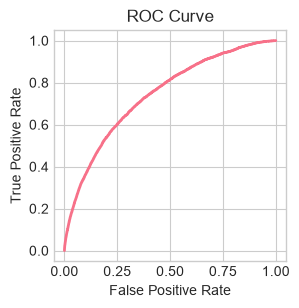

In [139]:
fpr , tpr , threshold = roc_curve(y_test , y_pred_proba)
plt.figure(figsize=(3,3))
plt.plot(fpr , tpr , lw=2) 

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")

plt.show()

In [ ]:
coef_df=pd.DataFrame({
      'columns': x_train.columns,
      'coefficient' :lr.coef_[0],
})

In [ ]:
coef_df

,columns,coefficient
0,Age,-0.590927
1,Income,-0.311478
2,LoanAmount,0.285249
3,CreditScore,-0.121901
4,MonthsEmployed,-0.340077
5,NumCreditLines,0.093052
6,InterestRate,0.458790
7,LoanTerm,-0.001820
8,DTIRatio,0.065822
9,Education,-0.070066


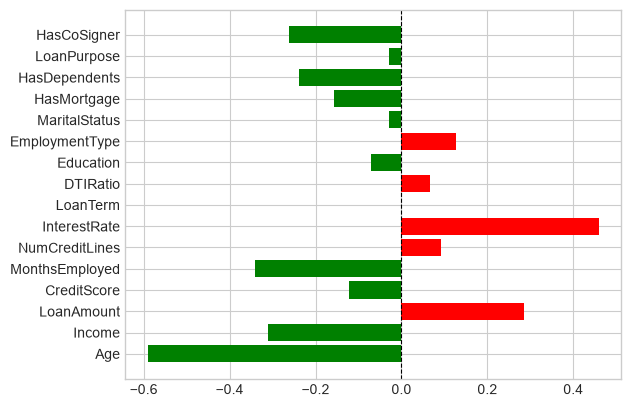

In [ ]:
plt.Figure(figsize=(3,3))
color=['r' if c >0 else 'g'for c in coef_df['coefficient']]
plt.barh(coef_df['columns'],coef_df['coefficient'],color=color)
plt.axvline(x=0 , color='black', linewidth= 0.8, linestyle='--')
plt.show()

In [ ]:
x_test.iloc[:2,:]

,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner
191605,48,104051,139338,325,1,1,24.53,24,0.84,2,3,1,0,1,0,0
236232,59,40930,129079,441,35,1,23.52,60,0.63,0,2,0,1,0,4,1


In [ ]:
import joblib

In [ ]:
joblib.dump(lr, 'LogisticRegression.pkl')

['LogisticRegression.pkl']

In [ ]:
model.predict(x_test.iloc[:2,:])

array([1, 1])

In [ ]:
model= joblib.load('LogisticRegression.pkl')